# Final Project — How Vehicle Weight Affects Fuel Efficiency
**Research question:** How does a car’s weight affect its fuel efficiency (miles per gallon)?  
**Course:** CS82A  
**GitHub repository:** https://github.com/washingtonjustin02smc/CS82A-repository (upload this folder before submission)

**Source:** [Auto MPG sample CSV](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv), derived from the historical Auto MPG data. **Canonical record and license:** [UCI Auto MPG](https://archive.ics.uci.edu/dataset/9/auto%2Bmpg), CC BY 4.0. Credit the data source and review UCI attribution terms. The seaborn-data repository says its sample datasets may have been modified; we use the particular linked CSV consistently. Dataset describes cars from model years 1970–1982, not modern vehicles.

## 1. Setup and load the open data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
charts_dir = Path("charts")
charts_dir.mkdir(exist_ok=True)
df = pd.read_csv(DATA_URL)
print("Original dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Original dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


Columns: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'name']


## 2. Documented cleaning log
1. Inspect missing values, duplicated complete rows, and numeric data types.
2. Convert MPG and weight to numeric, treating invalid entries as missing.
3. Remove rows without MPG or weight (these two fields are essential for this question).
4. Drop exact duplicate rows, if found, and report how many.
5. Do **not** delete rows just because horsepower is missing; it is not required for this analysis. Keep all other rows and state counts below.

In [2]:
print("Missing values before cleaning:")
print(df.isna().sum().to_string())
print("Duplicated full rows:", int(df.duplicated().sum()))
before_rows = len(df)
clean = df.copy()
clean["mpg"] = pd.to_numeric(clean["mpg"], errors="coerce")
clean["weight"] = pd.to_numeric(clean["weight"], errors="coerce")
missing_key = int(clean[["mpg", "weight"]].isna().any(axis=1).sum())
clean = clean.dropna(subset=["mpg", "weight"])
dups = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()
print(f"Cleaning log: started {before_rows} rows; removed {missing_key} with missing MPG/weight; removed {dups} exact duplicates; retained {len(clean)} rows.")
print("Missing values after cleaning:")
print(clean.isna().sum().to_string())

Missing values before cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
Duplicated full rows: 0
Cleaning log: started 398 rows; removed 0 with missing MPG/weight; removed 0 exact duplicates; retained 398 rows.
Missing values after cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0


## 3. Summary statistics and interpretation
Correlation measures association, **not causation**. The slope of a linear fit reports the estimated MPG difference for 1 additional pound of vehicle weight across the fitted range. For readability, also express it per 1,000 pounds.

In [3]:
summary = clean[["mpg", "weight"]].agg(["count", "mean", "median", "min", "max"])
display(summary.round(2))
r = clean["weight"].corr(clean["mpg"])
slope, intercept = np.polyfit(clean["weight"], clean["mpg"], 1)
print(f"Pearson correlation (weight vs MPG): {r:.3f}")
print(f"Estimated MPG change per 1,000 additional pounds: {slope*1000:.2f}")
print(f"Simple fitted line: MPG = {intercept:.2f} + ({slope:.5f} × weight in pounds)")

,mpg,weight
count,398.00,398.00
mean,23.51,2970.42
median,23.00,2803.50
min,9.00,1613.00
max,46.60,5140.00


Pearson correlation (weight vs MPG): -0.832
Estimated MPG change per 1,000 additional pounds: -7.68
Simple fitted line: MPG = 46.32 + (-0.00768 × weight in pounds)


## 4. Chart 1 — Vehicle weight vs fuel efficiency
Scatter plot of individual cars with an ordinary least-squares trend line. This chart directly answers the research question.

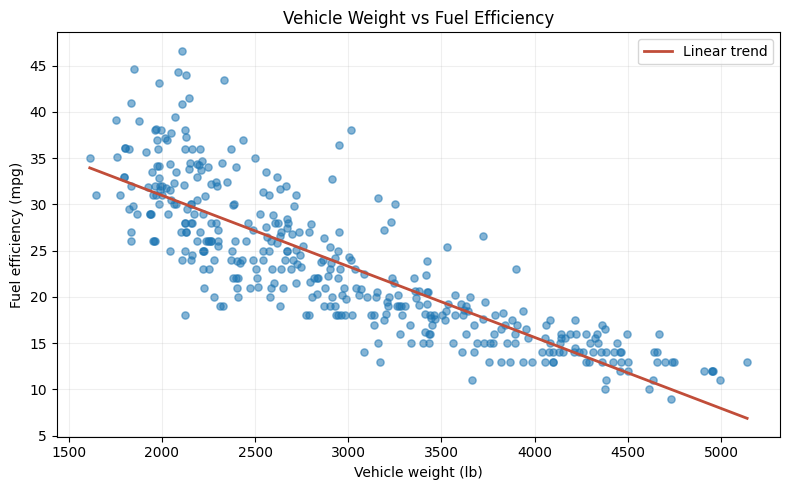

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(clean["weight"], clean["mpg"], alpha=.55, s=27)
x = np.linspace(clean["weight"].min(), clean["weight"].max(), 100)
ax.plot(x, intercept + slope*x, color="#C14D39", linewidth=2, label="Linear trend")
ax.set(title="Vehicle Weight vs Fuel Efficiency", xlabel="Vehicle weight (lb)", ylabel="Fuel efficiency (mpg)")
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(charts_dir / "01_weight_vs_mpg.png", dpi=170)
plt.show()

## 5. Chart 2 — Average MPG by model year
This chart provides historical context. In this dataset, model year 70 refers to 1970, etc.

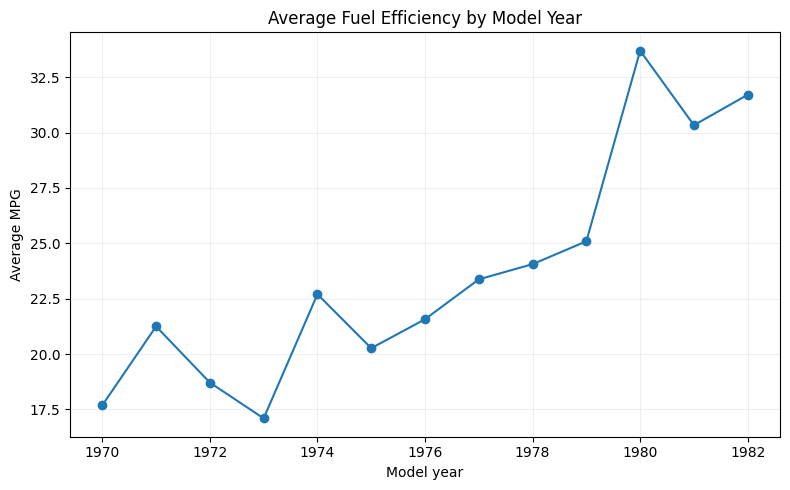

,model_year,mpg
0,70,17.69
1,71,21.25
2,72,18.71
3,73,17.10
4,74,22.70
5,75,20.27
6,76,21.57
7,77,23.38
8,78,24.06
9,79,25.09


In [5]:
by_year = clean.groupby("model_year", as_index=False)["mpg"].mean()
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(by_year["model_year"] + 1900, by_year["mpg"], marker="o")
ax.set(title="Average Fuel Efficiency by Model Year", xlabel="Model year", ylabel="Average MPG")
ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(charts_dir / "02_average_mpg_by_year.png", dpi=170)
plt.show()
display(by_year.round(2))

## 6. Chart 3 — Average MPG by cylinder count
Cylinder count is a descriptive comparison; differences should not be interpreted as solely caused by cylinder count.

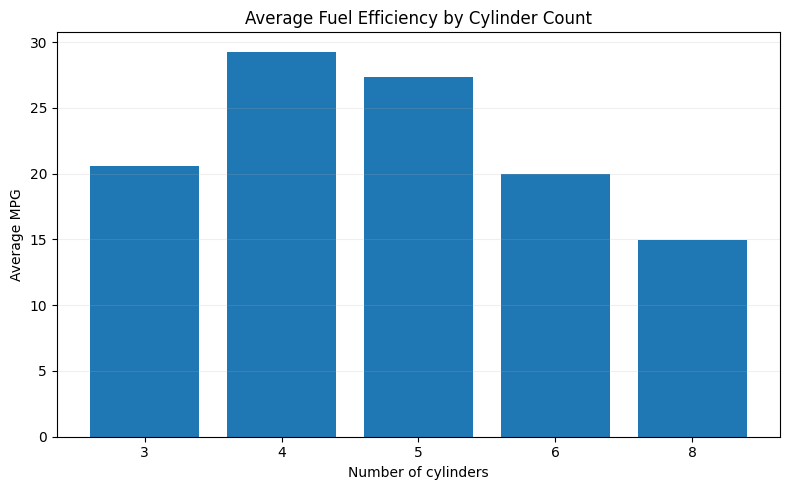

,cylinders,mean,count
0,3,20.55,4
1,4,29.29,204
2,5,27.37,3
3,6,19.99,84
4,8,14.96,103


In [6]:
by_cyl = clean.groupby("cylinders")["mpg"].agg(["mean", "count"]).reset_index()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(by_cyl["cylinders"].astype(str), by_cyl["mean"])
ax.set(title="Average Fuel Efficiency by Cylinder Count", xlabel="Number of cylinders", ylabel="Average MPG")
ax.set_ylim(bottom=0); ax.grid(axis="y", alpha=.2)
fig.tight_layout();fig.savefig(charts_dir / "03_average_mpg_by_cylinders.png", dpi=170)
plt.show()
display(by_cyl.round(2))

## 7. Findings and limitations

**Results from the executed analysis:**

- The dataset contains **398 vehicle records**; **0** were removed because of missing MPG/weight, and **0** exact duplicates were removed. The separate `horsepower` column has **6** missing values, but it was not needed for this question.
- Mean fuel efficiency was **23.51 MPG** and mean vehicle weight was **2,970.42 pounds**.
- Vehicle weight and MPG had a **strong negative association** (Pearson **r = -0.832**).
- The fitted straight line estimates **7.68 fewer MPG per additional 1,000 pounds** within this historical sample; this is an **association, not a causal effect**.
- Average MPG was **17.69 in model year 1970** and **31.71 in model year 1982**, with variation between years (including **33.70 in 1980**).
- Four-cylinder cars averaged **29.29 MPG** (n=204); six-cylinder cars averaged **19.99 MPG** (n=84); eight-cylinder cars averaged **14.96 MPG** (n=103). The 3-cylinder (n=4) and 5-cylinder (n=3) groups were too small for strong comparisons.

**Answer:** In these data, heavier vehicles generally had lower MPG. The weight-versus-MPG scatter plot supports this conclusion, but it does not prove that vehicle weight by itself caused the observed MPG differences.

**Limitations:** The cars are historical (model years 1970–1982), so these patterns may not represent present-day vehicles. Weight relates to cylinder count, engine size, model year, and other differences; these could influence both weight and MPG. This is observational data; group comparisons are descriptive, not controlled experiments.

**AI disclosure:** ChatGPT drafted the starting analysis and documentation and helped summarize the executed notebook output. All reported numeric results here come from the executed cells above. The student should independently review the outputs, clarify any changes made, and disclose actual AI assistance in the project log.


## 8. Reproducibility and checks
The following cell checks the expected schema and verifies that chart files exist after the analysis cells have run.

In [7]:
assert {"mpg", "weight", "model_year", "cylinders"}.issubset(clean.columns)
assert len(clean) > 0 and clean["mpg"].notna().all() and clean["weight"].notna().all()
for name in ["01_weight_vs_mpg.png", "02_average_mpg_by_year.png", "03_average_mpg_by_cylinders.png"]:
    assert (charts_dir / name).exists(), f"Missing chart: {name}"
print("All basic checks passed. Review your findings, then export the executed notebook as PDF.")

All basic checks passed. Review your findings, then export the executed notebook as PDF.
